In [1]:
import pandas as pd, numpy as np, torch, torch.nn as nn
url = ("https://earthquake.usgs.gov/fdsnws/event/1/query?format=csv"
       "&starttime=2015-01-01&endtime=2025-12-31&minmagnitude=5")
df = pd.read_csv(url)
df = df[["time","latitude","longitude","depth","mag"]].dropna()
df["time"] = pd.to_datetime(df["time"])
df = df.sort_values("time").reset_index(drop=True)
df["gap"] = df["time"].diff().dt.total_seconds().div(3600).fillna(0)
print(df.shape)

(19130, 6)


In [2]:
from sklearn.preprocessing import MinMaxScaler
feats = ["mag","depth","latitude","longitude","gap"]
n = len(df); i1, i2 = int(n*.7), int(n*.85)
sc = MinMaxScaler().fit(df[feats][:i1])
X = sc.transform(df[feats])
W = 10
xs = np.array([X[i:i+W] for i in range(n-W)])
ys = X[W:, 0]
tr, va = i1-W, i2-W
T = lambda a: torch.tensor(a, dtype=torch.float32)
Xtr,ytr = T(xs[:tr]),T(ys[:tr])
Xva,yva = T(xs[tr:va]),T(ys[tr:va])
Xte,yte = T(xs[va:]),T(ys[va:])
print(Xtr.shape, Xva.shape, Xte.shape)

torch.Size([13381, 10, 5]) torch.Size([2869, 10, 5]) torch.Size([2870, 10, 5])


In [3]:
class Net(nn.Module):
    def __init__(s):
        super().__init__()
        s.l = nn.LSTM(5, 32, batch_first=True)
        s.o = nn.Linear(32, 1)
    def forward(s, x):
        h,_ = s.l(x); return s.o(h[:,-1]).squeeze(1)
m = Net(); opt = torch.optim.Adam(m.parameters(), 1e-3); lf = nn.MSELoss()
for ep in range(30):
    m.train()
    for j in range(0, len(Xtr), 64):
        opt.zero_grad()
        loss = lf(m(Xtr[j:j+64]), ytr[j:j+64])
        loss.backward(); opt.step()
    m.eval()
    with torch.no_grad(): v = lf(m(Xva), yva).item()
    print(ep+1, round(loss.item(),5), round(v,5))

1 0.00299 0.01485
2 0.0031 0.01485
3 0.00322 0.01485
4 0.00331 0.01484
5 0.00337 0.01484
6 0.0034 0.01484
7 0.00342 0.01484
8 0.00343 0.01484
9 0.00342 0.01484
10 0.00341 0.01484
11 0.0034 0.01484
12 0.00339 0.01484
13 0.00338 0.01484
14 0.00336 0.01484
15 0.00335 0.01484
16 0.00333 0.01485
17 0.00332 0.01485
18 0.0033 0.01485
19 0.00328 0.01485
20 0.00327 0.01485
21 0.00325 0.01485
22 0.00322 0.01486
23 0.0032 0.01486
24 0.00318 0.01486
25 0.00316 0.01486
26 0.00314 0.01487
27 0.00312 0.01487
28 0.00311 0.01487
29 0.0031 0.01487
30 0.0031 0.01488


In [4]:
from sklearn.metrics import mean_absolute_error as mae, mean_squared_error as mse, r2_score
with torch.no_grad(): p = m(Xte).numpy()
lo, rg = sc.data_min_[0], sc.data_range_[0]
p = p*rg+lo; y = yte.numpy()*rg+lo
print("MAE", mae(y,p)); print("RMSE", mse(y,p)**.5); print("R2", r2_score(y,p))
base = np.full_like(y, df["mag"][:i1].mean())
print("Baseline MAE", mae(y,base))

MAE 0.284924889826232
RMSE 0.3914499444055324
R2 -0.002671590453051431
Baseline MAE 0.28782630264743947


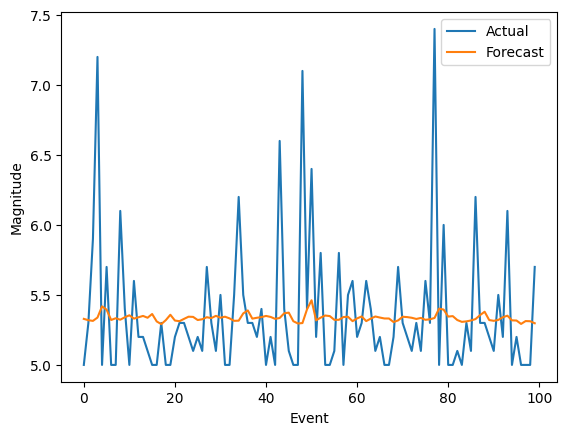

In [5]:
import matplotlib.pyplot as plt
plt.plot(y[:100], label="Actual"); plt.plot(p[:100], label="Forecast")
plt.legend(); plt.xlabel("Event"); plt.ylabel("Magnitude"); plt.show()